# 02 · Modelleme: Lojistik Regresyon ve LightGBM

**Amaç:** Yorumlanabilir bir temel model (lojistik regresyon) ile güçlü bir model
(LightGBM) kurmak, sınıf dengesizliği stratejilerini karşılaştırmak ve sonuçları
sızıntısız bir doğrulama düzeniyle raporlamak.

**Doğrulama düzeni**

| Adım | Veri | Ne için |
|---|---|---|
| Tabakalı ayrım | %80 eğitim / %20 test | Test seti en sonda **bir kez** kullanılır |
| 5 katlı tabakalı çapraz doğrulama | Yalnızca eğitim | Strateji ve hiperparametre seçimi, eşik seçimi |
| Zaman dışı kontrol | 1994–95 ile eğit, 1996'da test et | Modelin geleceğe genellenmesi |

Yeniden örnekleme (SMOTE vb.) her zaman **pipeline içinde**, yalnızca eğitim katlarına
uygulanır.

In [1]:
import json
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from imblearn.over_sampling import SMOTEN
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, RepeatedStratifiedKFold

from src import config, data, evaluation as ev, modeling, plotting

warnings.filterwarnings("ignore", category=UserWarning)
plotting.set_style()
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

df = data.load_clean()
X_train, X_test, y_train, y_test = data.train_test(df)
print(f"Train: {len(X_train):,} claims, {int(y_train.sum())} frauds ({y_train.mean():.2%})")
print(f"Test : {len(X_test):,} claims, {int(y_test.sum())} frauds ({y_test.mean():.2%})")
print(f"Features: {X_train.shape[1]}")

Train: 12,335 claims, 738 frauds (5.98%)
Test : 3,084 claims, 185 frauds (6.00%)
Features: 29


## 1. Metrik seçimi: neden accuracy değil?

| Metrik | Soru | Neden burada |
|---|---|---|
| **Precision** | İncelemeye gönderdiğim taleplerin kaçı gerçekten sahte? | Yanlış alarmın maliyeti: boşa giden inceleme, mağdur edilen dürüst müşteri |
| **Recall** | Sahtekârlıkların kaçını yakaladım? | Kaçırılan sahtekârlığın maliyeti: ödenen haksız tazminat |
| **F1** | Precision ve recall'un harmonik ortalaması | Tek bir eşikte ikisinin dengesi |
| **PR-AUC** | Tüm eşiklerde precision–recall dengesi | Eşikten bağımsız; pozitif sınıfa odaklı |

ROC-AUC ikincil olarak raporlanır. Nadir olaylarda ROC-AUC iyimser görünür, çünkü yanlış
pozitif oranının paydasında çok sayıda meşru talep vardır. PR-AUC için "rastgele model"
değeri 0,5 değil, **sahtekârlık oranıdır** (≈ 0,06).

In [2]:
always_legit_accuracy = 1 - y_test.mean()
print(f"Accuracy of a model that never flags anything : {always_legit_accuracy:.1%}  (recall = 0%)")
print(f"PR-AUC of a random ranking (= prevalence)     : {y_test.mean():.3f}")

Accuracy of a model that never flags anything : 94.0%  (recall = 0%)
PR-AUC of a random ranking (= prevalence)     : 0.060


## 2. Model olmadan ne kadar iyi? Kural tabanlı temel çizgi

Keşifsel analizde bulunan basit kural: *kusur poliçe sahibinde* ve *poliçe sorumluluk
(liability) değil*. Bir modelin değeri, bu kuralın üzerine ne eklediğiyle ölçülür.

In [3]:
train_df, test_df = df.loc[X_train.index], df.loc[X_test.index]


def rule_flag(frame: pd.DataFrame) -> np.ndarray:
    """Flag claims where the policy holder is at fault on a non-liability policy."""
    return ((frame["Fault"] == "Policy Holder") & (frame["BasePolicy"] != "Liability")).to_numpy()


rule_test = ev.threshold_metrics(y_test, rule_flag(test_df).astype(float), 0.5)

# A two-variable score: the training-set fraud rate of each Fault x BasePolicy segment.
segment_rate = train_df.groupby(["Fault", "BasePolicy"])[config.TARGET].mean()
segment_score_test = test_df.set_index(["Fault", "BasePolicy"]).index.map(segment_rate).to_numpy()
rule_pr_auc = average_precision_score(y_test, segment_score_test)

print(f"Rule on test set: flags {rule_test['flagged_share']:.1%} of claims, "
      f"precision {rule_test['precision']:.1%}, recall {rule_test['recall']:.1%}, F1 {rule_test['f1']:.3f}")
print(f"PR-AUC of the two-variable segment score: {rule_pr_auc:.3f}")

Rule on test set: flags 45.1% of claims, precision 12.6%, recall 94.6%, F1 0.222
PR-AUC of the two-variable segment score: 0.140


Kural sahtekârlıkların çoğunu kapsıyor ama taleplerin neredeyse yarısını işaretliyor;
precision düşük. Modelden beklenen: **bu büyük segmentin içinde** sıralama yapabilmek.

## 3. Yorumlanabilir model: odds oranları ve güven aralıkları

Önce tahmin için değil, **çıkarım** için bir lojistik regresyon: az sayıda değişken,
açık referans kategorileri, %95 güven aralıklı odds oranları (statsmodels, cezasız MLE).

Değişken seçimi notları:
- `Deductible` dahil edilmedi: "500" düzeyi "adres değişikliği 2–3 yıl" ile neredeyse
  aynı talepler (bkz. defter 01, bölüm 6.2); birlikte girdiklerinde katsayılar kararsızlaşır.
- `VehicleCategory` dahil edilmedi: `BasePolicy` ile güçlü biçimde örtüşüyor
  ("Sport" kategorisinin %93'ü sorumluluk poliçesi).
- `AddressChange_Claim` içindeki 4 kayıtlık "under 6 months" düzeyi "1 year" ile birleştirildi.

In [4]:
inference_df = train_df.copy()
inference_df["AddressChange"] = inference_df["AddressChange_Claim"].replace(
    {"under 6 months": "within 1 year", "1 year": "within 1 year"})

formula = (
    f"{config.TARGET} ~ C(Fault, Treatment('Third Party'))"
    " + C(BasePolicy, Treatment('Liability'))"
    " + C(AddressChange, Treatment('no change'))"
    " + C(PastNumberOfClaims, Treatment('none'))"
    " + C(Sex, Treatment('Male'))"
    " + C(AccidentArea, Treatment('Urban'))"
    " + C(AgentType, Treatment('External'))"
)
logit = smf.logit(formula, inference_df).fit(disp=0)

conf = logit.conf_int()
odds = pd.DataFrame({
    "odds_ratio": np.exp(logit.params),
    "ci_low": np.exp(conf[0]),
    "ci_high": np.exp(conf[1]),
    "p_value": logit.pvalues,
}).drop(index="Intercept")
odds.index = (odds.index.str.replace(r"C\((\w+), Treatment\('([^']+)'\)\)\[T\.(.+)\]",
                                     r"\1: \3 (vs \2)", regex=True))
print(f"Converged: {logit.mle_retvals['converged']}   McFadden pseudo-R2: {logit.prsquared:.3f}   "
      f"n = {int(logit.nobs):,}")
odds

Converged: True   McFadden pseudo-R2: 0.159   n = 12,335


,odds_ratio,ci_low,ci_high,p_value
Fault: Policy Holder (vs Third Party),13.0909,9.1397,18.7503,0.0000
BasePolicy: All Perils (vs Liability),19.5287,13.3399,28.5889,0.0000
BasePolicy: Collision (vs Liability),12.2901,8.4240,17.9306,0.0000
AddressChange: 2 to 3 years (vs no change),5.7867,3.9287,8.5233,0.0000
AddressChange: 4 to 8 years (vs no change),0.8015,0.5264,1.2203,0.3023
AddressChange: within 1 year (vs no change),1.5618,0.8359,2.9181,0.1622
PastNumberOfClaims: 1 (vs none),0.9667,0.7903,1.1826,0.7421
PastNumberOfClaims: 2 to 4 (vs none),1.0237,0.8455,1.2395,0.8100
PastNumberOfClaims: more than 4 (vs none),0.8254,0.5996,1.1362,0.2392
Sex: Female (vs Male),0.7956,0.6250,1.0127,0.0633


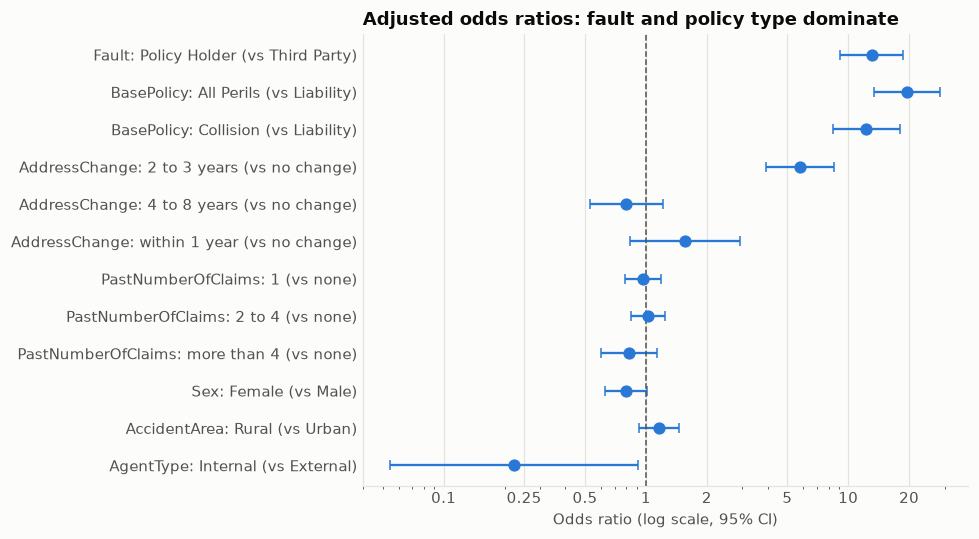

In [5]:
plot_df = odds.iloc[::-1]
y_pos = np.arange(len(plot_df))
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(plot_df["odds_ratio"], y_pos,
            xerr=[plot_df["odds_ratio"] - plot_df["ci_low"], plot_df["ci_high"] - plot_df["odds_ratio"]],
            fmt="o", color=plotting.BLUE, markersize=7, capsize=3, linewidth=1.5)
ax.axvline(1, color=plotting.INK_MUTED, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.1, 0.25, 0.5, 1, 2, 5, 10, 20])
ax.get_xaxis().set_major_formatter(plt.matplotlib.ticker.FormatStrFormatter("%g"))
ax.set_yticks(y_pos, plot_df.index)
ax.set_xlabel("Odds ratio (log scale, 95% CI)")
ax.set_title("Adjusted odds ratios: fault and policy type dominate")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plotting.save_fig(fig, "06_odds_ratios")
plt.show()

**Yorum (diğer değişkenler sabitken)**

- Kusurun poliçe sahibinde olması sahtekârlık odds'unu yaklaşık **13 kat** artırıyor
  (%95 GA yaklaşık 9–19).
- Sorumluluk poliçesine göre "All Perils" yaklaşık **20 kat**, "Collision" yaklaşık
  **12 kat** daha yüksek odds'a sahip.
- Adres değişikliği 2–3 yıl olanlarda odds yaklaşık **6 kat** (%95 GA yaklaşık 4–8,5).
  Hatırlatma: bu grup "muafiyet 500" kümesiyle neredeyse aynı (defter 01, bölüm 6.2).
- **Geçmiş hasar sayısı:** Tek değişkenli analizde güçlü görünen etki, poliçe türü ve
  kusur kontrol edildiğinde kayboluyor (tüm güven aralıkları 1'i içeriyor). Bu, defter
  01'deki karıştırıcı etki bulgusunu doğruluyor.
- Cinsiyet ve kaza bölgesi için güven aralıkları 1'i içeriyor; güçlü bir kanıt yok.
- Şirket içi acente (`AgentType = Internal`) için odds oranı düşük görünüyor ama güven
  aralığı çok geniş (yaklaşık 0,05–0,92): grup küçük, tahmin belirsiz.

Güven aralıklarının genişliği önemli: sahtekârlık nadir olduğu için küçük düzeylerdeki
tahminler belirsiz.

## 4. Sınıf dengesizliği stratejilerinin karşılaştırılması

Dört strateji, iki model, aynı 5 katlı çapraz doğrulama:

| Strateji | Ne yapar |
|---|---|
| `none` | Hiçbir şey; model gerçek sınıf oranını görür |
| `class_weight` | Kayıp fonksiyonunda azınlık sınıfına ters orantılı ağırlık |
| `undersample` | Çoğunluk sınıfından rastgele örnek atar (1:1) |
| `smoten` | SMOTE-N: kategorik veriler için sentetik azınlık örnekleri üretir |

Klasik SMOTE kullanılmadı: değişkenlerin neredeyse tamamı kategorik ve kategori kodları
arasında doğrusal ara değer üretmek anlamsız. SMOTE-N bu durum için tasarlanmış türevdir.

İki ayrı soru soruluyor: (1) strateji **sıralama kalitesini** (PR-AUC) değiştiriyor mu?
(2) varsayılan 0,5 eşiğinde ne oluyor, eşik ayarlanınca ne oluyor?

In [6]:
builders = {"Logistic regression": modeling.make_logreg, "LightGBM": modeling.make_lgbm}
rows, oof_by_strategy = [], {}
for model_name, build in builders.items():
    for strategy in modeling.STRATEGIES:
        folds, oof = modeling.cross_validate(build(strategy), X_train, y_train)
        oof_by_strategy[(model_name, strategy)] = oof
        at_default = ev.threshold_metrics(y_train, oof, 0.5)
        at_best = ev.threshold_metrics(y_train, oof, ev.best_f1_threshold(y_train, oof))
        rows.append({
            "model": model_name, "strategy": strategy,
            "pr_auc_mean": folds["pr_auc"].mean(), "pr_auc_std": folds["pr_auc"].std(),
            "roc_auc_mean": folds["roc_auc"].mean(),
            "precision@0.5": at_default["precision"], "recall@0.5": at_default["recall"],
            "f1@0.5": at_default["f1"],
            "best_f1": at_best["f1"], "best_f1_threshold": at_best["threshold"],
        })
strategy_table = pd.DataFrame(rows)
strategy_table

,model,strategy,pr_auc_mean,pr_auc_std,roc_auc_mean,precision@0.5,recall@0.5,f1@0.5,best_f1,best_f1_threshold
0,Logistic regression,none,0.1530,0.0107,0.7917,0.2000,0.0095,0.0181,0.2358,0.0956
1,Logistic regression,class_weight,0.1515,0.0143,0.7962,0.1337,0.8211,0.2300,0.2386,0.6045
2,Logistic regression,undersample,0.1429,0.0166,0.7852,0.1282,0.8076,0.2213,0.2273,0.5905
3,Logistic regression,smoten,0.1311,0.0087,0.7302,0.1416,0.3997,0.2091,0.2157,0.4115
4,LightGBM,none,0.2003,0.0304,0.8101,0.8056,0.0393,0.0749,0.2506,0.0734
5,LightGBM,class_weight,0.1876,0.0282,0.8049,0.1552,0.4973,0.2366,0.2440,0.4419
6,LightGBM,undersample,0.1532,0.0161,0.7962,0.1337,0.8130,0.2296,0.2423,0.7245
7,LightGBM,smoten,0.1642,0.0174,0.7840,0.1787,0.2182,0.1965,0.2297,0.1676


In [7]:
best_strategy = (strategy_table.loc[strategy_table.groupby("model")["pr_auc_mean"].idxmax()]
                 .set_index("model")["strategy"].to_dict())
print("Strategy with the highest CV PR-AUC per model:", best_strategy)

Strategy with the highest CV PR-AUC per model: {'LightGBM': 'none', 'Logistic regression': 'none'}


**Bu tablo projenin en önemli metodolojik bulgusu:**

1. **Yeniden örnekleme sıralama kalitesini artırmıyor.** İki modelde de en yüksek
   PR-AUC hiçbir şey yapılmadığında (`none`) elde ediliyor; `undersample` ve `smoten`
   daha kötü. `none` ile `class_weight` arasındaki fark ise katlar arası standart sapmanın
   içinde.
2. **Stratejilerin asıl etkisi çalışma noktasını kaydırmak.** `none` ile 0,5 eşiğinde
   recall yalnızca %1–4 (model çok az talebe %50'den fazla olasılık veriyor);
   `class_weight` ile aynı eşikte recall %50–82'ye çıkıyor, precision %13–16'ya düşüyor.
3. **Eşik ayarlandığında fark kapanıyor.** `best_f1` sütununda tüm stratejiler 0,22–0,25
   aralığında; LightGBM'de en yüksek değer yine `none` stratejisinde.

**Sonuç:** Sınıf dengesizliği bu projede eğitim verisini değiştirerek değil, üç yerde ele
alınıyor: tabakalı doğrulama, dengesizliğe uygun metrikler ve **iş maliyetine göre eşik
seçimi** (defter 04). Ek avantaj: yeniden örnekleme yapılmadığında modelin olasılıkları
gerçek sahtekârlık oranına göre kalibre kalır; bu, maliyet temelli eşik seçimini
doğrudan mümkün kılar.

## 5. Uyarı: SMOTE ayrımdan önce uygulanırsa ne olur?

Bu veri setiyle yapılmış birçok açık çalışma %90'ın üzerinde F1 raporluyor. Yaygın neden:
yeniden örneklemenin **veri bölünmeden önce** yapılması. Sentetik örnekler gerçek
örneklerin komşularından türetildiği için doğrulama katına sızar; ayrıca doğrulama katı
da yapay olarak dengelenmiş olur. Aşağıda aynı model iki şekilde değerlendiriliyor.

In [8]:
flexible_params = dict(n_estimators=500, learning_rate=0.1, num_leaves=31, min_child_samples=20)

# Wrong: resample the whole training set first, then cross-validate on the resampled data.
X_leaky, y_leaky = SMOTEN(random_state=config.RANDOM_STATE).fit_resample(X_train, y_train)
leaky_folds, leaky_oof = modeling.cross_validate(modeling.make_lgbm("none", **flexible_params), X_leaky, y_leaky)
leaky = ev.threshold_metrics(y_leaky, leaky_oof, 0.5)

# Right: the same sampler inside the pipeline, fitted on training folds only.
honest_folds, honest_oof = modeling.cross_validate(modeling.make_lgbm("smoten", **flexible_params), X_train, y_train)
honest = ev.threshold_metrics(y_train, honest_oof, 0.5)

leak_table = pd.DataFrame({
    "SMOTE-N before CV (leaky)": {"pr_auc": leaky_folds["pr_auc"].mean(), "f1@0.5": leaky["f1"],
                                  "precision@0.5": leaky["precision"], "recall@0.5": leaky["recall"],
                                  "accuracy@0.5": leaky["accuracy"]},
    "SMOTE-N inside CV (correct)": {"pr_auc": honest_folds["pr_auc"].mean(), "f1@0.5": honest["f1"],
                                    "precision@0.5": honest["precision"], "recall@0.5": honest["recall"],
                                    "accuracy@0.5": honest["accuracy"]},
}).T
leak_table

,pr_auc,f1@0.5,precision@0.5,recall@0.5,accuracy@0.5
SMOTE-N before CV (leaky),0.9925,0.9611,0.9675,0.9548,0.9614
SMOTE-N inside CV (correct),0.1758,0.1593,0.2296,0.1220,0.9230


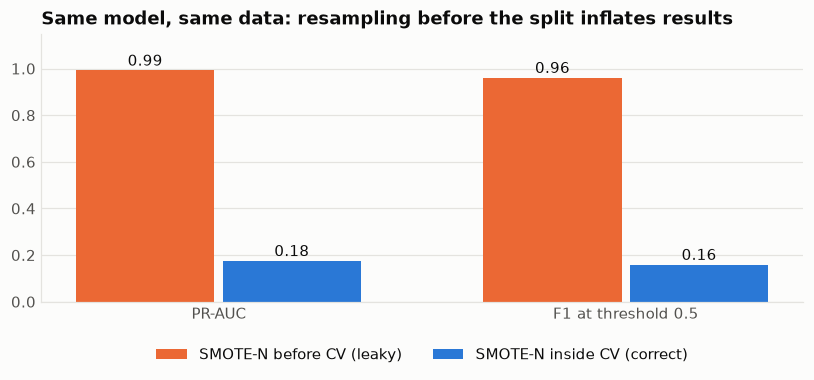

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
metrics = ["pr_auc", "f1@0.5"]
labels = ["PR-AUC", "F1 at threshold 0.5"]
x = np.arange(len(metrics))
width = 0.34
for offset, (name, color) in zip([-width / 2 - 0.01, width / 2 + 0.01],
                                 [("SMOTE-N before CV (leaky)", plotting.ORANGE),
                                  ("SMOTE-N inside CV (correct)", plotting.BLUE)]):
    values = leak_table.loc[name, metrics].to_numpy(dtype=float)
    bars = ax.bar(x + offset, values, width, color=color, label=name)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.02, f"{value:.2f}",
                ha="center", color=plotting.INK)
ax.set_xticks(x, labels)
ax.set_ylim(0, 1.15)
ax.set_title("Same model, same data: resampling before the split inflates results")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="x", visible=False)
fig.tight_layout()
plotting.save_fig(fig, "07_smote_leakage")
plt.show()

Aynı model, aynı veri. Yanlış kurulumda sonuçlar mükemmele yakın; doğru kurulumda
gerçek performans ortaya çıkıyor. Bu projede raporlanan sayılar mütevazı ama **gerçek**:
yeni gelen taleplerde beklenecek performansı yansıtıyor.

## 6. Hiperparametre ayarı

Seçim ölçütü PR-AUC. Katlar arası oynaklık yüksek olduğu için (pozitif sınıf küçük)
ayar sırasında 3 kez tekrarlı 5 katlı çapraz doğrulama kullanılır.

In [10]:
tuning_cv = RepeatedStratifiedKFold(n_splits=config.N_SPLITS, n_repeats=3,
                                    random_state=config.RANDOM_STATE)

logreg_search = GridSearchCV(
    modeling.make_logreg(best_strategy["Logistic regression"]),
    {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]},
    scoring="average_precision", cv=tuning_cv, n_jobs=2,
).fit(X_train, y_train)
logreg_cv = pd.DataFrame(logreg_search.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]]
print(logreg_cv.to_string(index=False))
print("Best C:", logreg_search.best_params_["model__C"])

 param_model__C  mean_test_score  std_test_score
         0.0100           0.1515          0.0140
         0.0300           0.1531          0.0138
         0.1000           0.1552          0.0137
         0.3000           0.1570          0.0135
         1.0000           0.1579          0.0125
         3.0000           0.1585          0.0121
        10.0000           0.1587          0.0122
        30.0000           0.1587          0.0119
       100.0000           0.1583          0.0114
Best C: 10


In [11]:
lgbm_space = {
    "model__n_estimators": [100, 200, 300, 500, 800],
    "model__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1],
    "model__num_leaves": [4, 7, 15, 31],
    "model__min_child_samples": [20, 40, 80, 150],
    "model__subsample": [0.6, 0.8, 1.0],
    "model__colsample_bytree": [0.4, 0.6, 0.8, 1.0],
    "model__reg_lambda": [0, 1, 5, 20],
}
lgbm_search = RandomizedSearchCV(
    modeling.make_lgbm(best_strategy["LightGBM"]), lgbm_space, n_iter=40,
    scoring="average_precision", cv=tuning_cv, n_jobs=2, random_state=config.RANDOM_STATE,
).fit(X_train, y_train)

lgbm_cv = pd.DataFrame(lgbm_search.cv_results_).sort_values("rank_test_score")
print(lgbm_cv[["mean_test_score", "std_test_score"]].head(5).to_string(index=False))
lgbm_params = {k.replace("model__", ""): v for k, v in lgbm_search.best_params_.items()}
print("Best parameters:", lgbm_params)
print(f"Spread of mean CV PR-AUC across the 40 candidates: "
      f"{lgbm_cv['mean_test_score'].min():.3f} - {lgbm_cv['mean_test_score'].max():.3f}")

 mean_test_score  std_test_score
          0.2205          0.0368
          0.2186          0.0344
          0.2181          0.0324
          0.2170          0.0334
          0.2157          0.0332
Best parameters: {'subsample': 1.0, 'reg_lambda': 0, 'num_leaves': 7, 'n_estimators': 300, 'min_child_samples': 80, 'learning_rate': 0.01, 'colsample_bytree': 0.6}
Spread of mean CV PR-AUC across the 40 candidates: 0.153 - 0.220


Seçilen LightGBM oldukça **sade** bir model (az yaprak, düşük öğrenme oranı): 738 pozitif
örnekle karmaşık bir model öğrenmeye yetecek veri yok. En iyi adaylar arasındaki farklar
katlar arası standart sapmadan küçük; yani ayarın katkısı sınırlı, asıl bilgi veride.

## 7. Nihai modeller ve test seti değerlendirmesi

Eşik, eğitim setindeki **kat dışı (out-of-fold)** tahminler üzerinde F1'i en yükselten
değer olarak seçilir; test seti eşik seçiminde kullanılmaz. (İş maliyetine göre eşik
seçimi defter 04'te.)

In [12]:
final_models = {
    "Logistic regression": modeling.make_logreg(best_strategy["Logistic regression"],
                                                C=logreg_search.best_params_["model__C"]),
    "LightGBM": modeling.make_lgbm(best_strategy["LightGBM"], **lgbm_params),
}

oof_scores, test_scores, thresholds, results = {}, {}, {}, []
for name, pipeline in final_models.items():
    folds, oof = modeling.cross_validate(pipeline, X_train, y_train)
    pipeline.fit(X_train, y_train)
    scores = pipeline.predict_proba(X_test)[:, 1]
    oof_scores[name], test_scores[name] = oof, scores
    thresholds[name] = ev.best_f1_threshold(y_train, oof)

    pr_auc, pr_low, pr_high = ev.bootstrap_ci(y_test, scores)
    at_threshold = ev.threshold_metrics(y_test, scores, thresholds[name])
    results.append({
        "model": name,
        "cv_pr_auc": folds["pr_auc"].mean(), "cv_pr_auc_std": folds["pr_auc"].std(),
        "test_pr_auc": pr_auc, "test_pr_auc_ci_low": pr_low, "test_pr_auc_ci_high": pr_high,
        "test_roc_auc": roc_auc_score(y_test, scores),
        **{f"test_{k}": at_threshold[k] for k in
           ["threshold", "precision", "recall", "f1", "flagged_share", "tp", "fp", "fn", "tn"]},
    })
results_table = pd.DataFrame(results).set_index("model")
results_table.T

model,Logistic regression,LightGBM
cv_pr_auc,0.1538,0.2201
cv_pr_auc_std,0.0120,0.0487
test_pr_auc,0.1644,0.2034
test_pr_auc_ci_low,0.1356,0.1642
test_pr_auc_ci_high,0.2042,0.2540
test_roc_auc,0.8096,0.8224
test_threshold,0.1033,0.1239
test_precision,0.1553,0.1814
test_recall,0.6162,0.4541
test_f1,0.2481,0.2593


In [13]:
difference = ev.paired_bootstrap_diff(y_test, test_scores["LightGBM"], test_scores["Logistic regression"])
print(f"Test PR-AUC difference (LightGBM - logistic regression): {difference['diff']:+.3f} "
      f"(95% bootstrap CI {difference['ci_low']:+.3f} to {difference['ci_high']:+.3f}); "
      f"LightGBM better in {difference['share_a_better']:.1%} of resamples")
print(f"Lift over random ranking: LightGBM {results_table.loc['LightGBM', 'test_pr_auc'] / y_test.mean():.1f}x, "
      f"logistic regression {results_table.loc['Logistic regression', 'test_pr_auc'] / y_test.mean():.1f}x, "
      f"segment rule {rule_pr_auc / y_test.mean():.1f}x")

Test PR-AUC difference (LightGBM - logistic regression): +0.039 (95% bootstrap CI +0.005 to +0.076); LightGBM better in 99.0% of resamples
Lift over random ranking: LightGBM 3.4x, logistic regression 2.7x, segment rule 2.3x


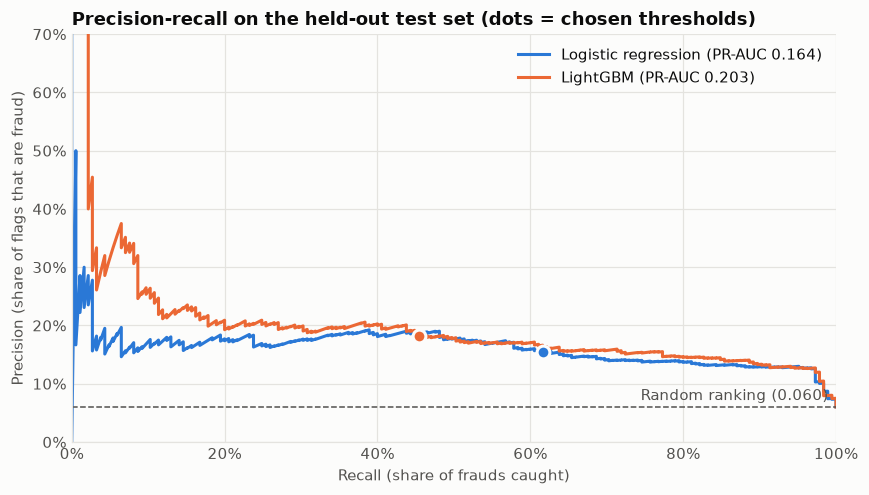

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.6))
for name, color in [("Logistic regression", plotting.COLOR_LOGREG), ("LightGBM", plotting.COLOR_LGBM)]:
    precision, recall, _ = precision_recall_curve(y_test, test_scores[name])
    ax.plot(recall, precision, color=color,
            label=f"{name} (PR-AUC {results_table.loc[name, 'test_pr_auc']:.3f})")
    point = results_table.loc[name]
    ax.scatter(point["test_recall"], point["test_precision"], s=70, color=color,
               edgecolor=plotting.SURFACE, linewidth=2, zorder=3)
ax.axhline(y_test.mean(), color=plotting.INK_MUTED, linestyle="--", linewidth=1)
ax.text(0.99, y_test.mean() + 0.012, f"Random ranking ({y_test.mean():.3f})", ha="right",
        color=plotting.INK_MUTED)
ax.set_xlabel("Recall (share of frauds caught)")
ax.set_ylabel("Precision (share of flags that are fraud)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 0.7)
plotting.pct_axis(ax, "x")
plotting.pct_axis(ax, "y")
ax.set_title("Precision-recall on the held-out test set (dots = chosen thresholds)")
ax.legend(loc="upper right")
fig.tight_layout()
plotting.save_fig(fig, "08_precision_recall_curve")
plt.show()

**Test seti sonuçları nasıl okunmalı?**

- LightGBM'in PR-AUC değeri rastgele sıralamanın 3 katından fazla ve lojistik
  regresyondan anlamlı biçimde yüksek (eşleştirilmiş bootstrap farkının güven aralığı
  sıfırı içermiyor).
- **Kazanç nerede?** PR eğrisinde iki model recall %40'tan sonra neredeyse üst üste.
  LightGBM'in üstünlüğü en yüksek skorlu taleplerde: listenin en başında precision
  belirgin biçimde daha yüksek. Yani model, sınırlı kapasiteli bir inceleme ekibine
  "önce hangi dosyalara bakmalı" sorusunda değer katıyor.
- Mutlak düzey mütevazı: bu veriyle mükemmel ayrım mümkün değil. Değişkenler talebin
  *türünü* tanımlıyor, *davranışını* değil (hasar tutarı, tamirhane, önceki şüpheli
  kayıtlar gibi bilgiler yok).
- Güven aralıkları geniş, çünkü test setinde yalnızca 185 sahtekârlık var. Tek bir sayı
  yerine aralık raporlamak bu yüzden önemli.
- ROC-AUC ≈ 0,8 "iyi" görünürken PR-AUC ≈ 0,2: nadir olaylarda ROC-AUC'nin neden
  iyimser olduğunun somut örneği.

## 8. Zaman dışı doğrulama (out-of-time)

Rastgele ayrım, modelin *aynı dönemdeki* taleplere genellenmesini ölçer. Gerçekte model
geçmiş veriyle eğitilip gelecekteki taleplerde kullanılır. Aynı hiperparametrelerle:
1994–1995 ile eğit, 1996'da test et.

In [15]:
X_all, y_all = data.split_features_target(df)
past, future = (df["Year"] <= 1995).to_numpy(), (df["Year"] == 1996).to_numpy()

oot_rows = []
for name, pipeline in final_models.items():
    model = modeling.clone(pipeline).fit(X_all[past], y_all[past])
    scores = model.predict_proba(X_all[future])[:, 1]
    pr_auc, low, high = ev.bootstrap_ci(y_all[future], scores)
    oot_rows.append({"model": name, "train_rows": int(past.sum()), "test_rows": int(future.sum()),
                     "test_frauds": int(y_all[future].sum()), "prevalence": y_all[future].mean(),
                     "pr_auc": pr_auc, "ci_low": low, "ci_high": high,
                     "lift_over_random": pr_auc / y_all[future].mean(),
                     "roc_auc": roc_auc_score(y_all[future], scores)})
oot_table = pd.DataFrame(oot_rows).set_index("model")
oot_table

,train_rows,test_rows,test_frauds,prevalence,pr_auc,ci_low,ci_high,lift_over_random,roc_auc
model,,,,,,,,,
Logistic regression,11336,4083,213,0.0522,0.0960,0.0814,0.1177,1.8406,0.7375
LightGBM,11336,4083,213,0.0522,0.1374,0.1068,0.1739,2.6330,0.7509


**Zaman dışı testte performans belirgin biçimde düşüyor.** LightGBM'in rastgele
sıralamaya göre üstünlüğü rastgele ayrımda 3,4 kat iken burada 2,6 kat; ROC-AUC 0,82'den
0,75'e iniyor. Lojistik regresyonda düşüş daha da büyük.

Bu, raporlamada dürüst olunması gereken bir nokta: rastgele ayrım, canlıdaki performansı
**olduğundan iyi** gösterir. Sahtekârlık kalıpları zamanla değişir (defter 01'de oranın
yıllar içinde düştüğü görülmüştü). Canlı kullanımda performansın düzenli izlenmesi ve
modelin periyodik olarak yeniden eğitilmesi gerekir.

## 9. Hassas değişkenler olmadan model

Cinsiyet, medeni durum ve yaş, sigortacılıkta hukuken ve etik olarak hassas
değişkenlerdir. Bu değişkenler çıkarıldığında performans ne kadar değişiyor?

In [16]:
neutral_features = [f for f in config.FEATURES if f not in config.SENSITIVE_FEATURES]
full_folds, _ = modeling.cross_validate(final_models["LightGBM"], X_train, y_train)
neutral_folds, _ = modeling.cross_validate(final_models["LightGBM"], X_train[neutral_features], y_train)
ablation = pd.DataFrame({
    "all features": full_folds["pr_auc"],
    "without Sex, MaritalStatus, AgeOfPolicyHolder": neutral_folds["pr_auc"],
})
print(ablation.agg(["mean", "std"]).T)
print(f"Mean paired difference (without - with): {(ablation.iloc[:, 1] - ablation.iloc[:, 0]).mean():+.4f}")

                                                mean    std
all features                                  0.2201 0.0487
without Sex, MaritalStatus, AgeOfPolicyHolder 0.2058 0.0452
Mean paired difference (without - with): -0.0143


Hassas değişkenler çıkarıldığında ortalama PR-AUC yaklaşık 0,014 düşüyor; bu fark katlar
arası standart sapmanın (≈ 0,05) oldukça altında. Yani bu üç değişken olmadan da benzer
performans elde edilebiliyor; canlı kullanımda daha güvenli seçenek bu olurdu
(ayrıntı: defter 04). Not: değişkeni çıkarmak tek başına adaleti
garanti etmez; diğer değişkenler üzerinden dolaylı etki ayrıca denetlenmelidir.

## 10. Çıktıların kaydedilmesi

Sonraki defterler (SHAP ve iş yorumu) burada kaydedilen modeli ve tahminleri kullanır.

In [17]:
config.MODELS_DIR.mkdir(exist_ok=True)
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(final_models["LightGBM"], config.MODELS_DIR / "lightgbm.joblib")
joblib.dump(final_models["Logistic regression"], config.MODELS_DIR / "logreg.joblib")

pd.DataFrame({"y": y_train, "oof_lightgbm": oof_scores["LightGBM"],
              "oof_logreg": oof_scores["Logistic regression"]}, index=X_train.index
             ).to_csv(config.MODELS_DIR / "train_oof_predictions.csv", index_label="row_id")
pd.DataFrame({"y": y_test, "lightgbm": test_scores["LightGBM"],
              "logreg": test_scores["Logistic regression"]}, index=X_test.index
             ).to_csv(config.MODELS_DIR / "test_predictions.csv", index_label="row_id")

strategy_table.to_csv(config.METRICS_DIR / "imbalance_strategies_cv.csv", index=False)
odds.to_csv(config.METRICS_DIR / "odds_ratios.csv")
summary = {
    "train_rows": len(X_train), "test_rows": len(X_test),
    "train_frauds": int(y_train.sum()), "test_frauds": int(y_test.sum()),
    "test_prevalence": float(y_test.mean()),
    "rule_baseline": {**{k: rule_test[k] for k in ["precision", "recall", "f1", "flagged_share"]},
                      "segment_score_pr_auc": float(rule_pr_auc)},
    "best_strategy": best_strategy,
    "logreg_C": logreg_search.best_params_["model__C"],
    "lightgbm_params": lgbm_params,
    "test_results": json.loads(results_table.to_json(orient="index")),
    "lightgbm_minus_logreg_pr_auc": difference,
    "leakage_demo": json.loads(leak_table.to_json(orient="index")),
    "out_of_time": json.loads(oot_table.to_json(orient="index")),
    "sensitive_feature_ablation_cv_pr_auc": {k: float(v) for k, v in ablation.mean().items()},
}
(config.METRICS_DIR / "model_metrics.json").write_text(json.dumps(summary, indent=2))
print("Saved models to", config.MODELS_DIR.relative_to(config.ROOT))
print("Saved metrics to", config.METRICS_DIR.relative_to(config.ROOT))

Saved models to models
Saved metrics to reports/metrics


## 11. Özet

1. **Metodoloji:** Test seti bir kez kullanıldı; strateji, hiperparametre ve eşik seçimi
   yalnızca eğitim verisindeki çapraz doğrulamayla yapıldı.
2. **Dengesizlik:** Yeniden örnekleme (alt örnekleme, SMOTE-N) sıralama kalitesini
   artırmadı. Dengesizlik; tabakalı doğrulama, uygun metrikler ve eşik seçimiyle ele alındı.
3. **Sızıntı:** SMOTE'un ayrımdan önce uygulanması sonuçları yapay biçimde mükemmele
   yaklaştırıyor; bu projede bilinçli olarak kaçınıldı ve fark gösterildi.
4. **Performans:** LightGBM, lojistik regresyondan ve iki değişkenli kuraldan daha iyi
   sıralıyor; mutlak düzey mütevazı ve güven aralıklarıyla raporlandı. Zaman dışı testte
   performans düşüyor: canlıda izleme şart.
5. **Yorumlanabilirlik:** Odds oranları kusur ve poliçe türünün baskın olduğunu,
   geçmiş hasar sayısının ise bağımsız bir etkisinin olmadığını gösteriyor.